# 02.4 · Riemannian MDM — klasyfikacja kowariancji EEG

## 1. Importy i konfiguracja

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn import __version__ as sklearn_version

def sha256_file(path, chunk_size=8*1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            h.update(chunk)
    return h.hexdigest()

print('NumPy:', np.__version__, 'scikit-learn:', sklearn_version)
import pyriemann
from pyriemann.estimation import Covariances
from pyriemann.classification import MDM
print('pyRiemann:',pyriemann.__version__)

NumPy: 1.26.4 scikit-learn: 1.5.2
pyRiemann: 0.7


In [ ]:

TRYB_TESTOWY = False
USE_ICA = True
USE_ALL_64_CHANNELS = True
ROOT = Path.cwd()  
TAG = ('ica' if USE_ICA else 'bez_ica') + ('_64ch' if USE_ALL_64_CHANNELS else '_19ch')
DATA_DIR = ROOT / (('benchmark_data_demo_' if TRYB_TESTOWY else 'benchmark_data_') + TAG)
RESULTS_BASE = ROOT / (('results_demo_' if TRYB_TESTOWY else 'results_') + TAG)
FOLDS_TO_RUN = [1, 2, 3, 4, 5]  
SEED = 42
THRESHOLD = 0.5  
print('Dane:', DATA_DIR)
print('Foldy:', FOLDS_TO_RUN)
RESULTS_DIR = RESULTS_BASE / 'riemann_mdm'
COVARIANCE_ESTIMATOR = 'oas'
RIEMANN_METRIC = 'riemann'
MDM_N_JOBS = 1
COV_BATCH_SIZE = 128
USE_COVARIANCE_CACHE = True
print('Kowariancja:', COVARIANCE_ESTIMATOR, 'metryka:',RIEMANN_METRIC)

Dane: /home/eliza/mgr-phd/benchmark_data_ica_64ch
Foldy: [1, 2, 3, 4, 5]
Kowariancja: oas metryka: riemann


## 2. Wczytanie danych notebooka 01 i kontrola rozłączności osób

In [3]:
required = [DATA_DIR/'epochs.npz', DATA_DIR/'splits.npz', DATA_DIR/'manifest.json']
for f in required:
    if not f.is_file():
        raise FileNotFoundError(f'Brakuje {f}; uruchom najpierw notebook 01 lub popraw DATA_DIR.')

with np.load(DATA_DIR/'epochs.npz', allow_pickle=False) as d:
    X = d['X'].astype(np.float32, copy=False)
    y = d['y'].astype(np.uint8, copy=False)
    subjects = d['subjects'].astype(str)
    trial_ids = d['trial_ids'].astype(str)
    channel_names = [str(v) for v in d['channel_names']]
with np.load(DATA_DIR/'splits.npz', allow_pickle=False) as d:
    splits = {k: d[k].astype(np.int32) for k in d.files}
manifest = json.loads((DATA_DIR/'manifest.json').read_text(encoding='utf-8'))

assert manifest['demo_mode'] == TRYB_TESTOWY, 'Nieprawidłowy TRYB_TESTOWY względem 01.'
assert bool(manifest['ica']) == USE_ICA, 'Nieprawidłowy USE_ICA względem 01.'
assert manifest['channel_mode'] == ('64' if USE_ALL_64_CHANNELS else '19'), 'Inne kanały niż w 01.'
assert manifest['units'] == 'microvolts', 'Spodziewano się µV.'
assert X.ndim == 3 and X.shape[1] == len(channel_names)
assert len(y) == len(X) == len(subjects) == len(trial_ids)
assert len(set(trial_ids)) == len(trial_ids)
assert set(np.unique(y)) == {0, 1}
assert np.isfinite(X).all(), 'W danych są NaN lub inf.'
assert sorted(set(FOLDS_TO_RUN)) == sorted(FOLDS_TO_RUN)
assert FOLDS_TO_RUN and all(isinstance(f, int) and 1 <= f <= 5 for f in FOLDS_TO_RUN)
assert np.isclose(float(manifest['sampling_rate_hz']), 160.0)

for fold in FOLDS_TO_RUN:
    tr, va, te = (splits[f'{kind}_{fold}'] for kind in ('train', 'val', 'test'))
    assert all(len(np.unique(s)) == len(s) for s in (tr,va,te))
    assert not (set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
    ps = [set(subjects[idx]) for idx in (tr,va,te)]
    assert not (ps[0]&ps[1] or ps[0]&ps[2] or ps[1]&ps[2]), f'Fold {fold}: przeciek uczestników!'
    assert all(set(np.unique(y[ix])) == {0,1} for ix in (tr,va,te))

epochs_sha256 = sha256_file(DATA_DIR/'epochs.npz')
splits_sha256 = sha256_file(DATA_DIR/'splits.npz')
print('Dane:', X.shape, 'µV | osoby:', len(np.unique(subjects)))
print('Klasy:', dict(zip(*np.unique(y,return_counts=True))))
print('SHA256 epok:', epochs_sha256[:18], '...')
print('SHA256 foldów:', splits_sha256[:18], '...')
print('Kontrola podziałów i ICA zgodna z notebookiem 01: OK')

Dane: (9844, 64, 481) µV | osoby: 109
Klasy: {0: 4894, 1: 4950}
SHA256 epok: b81d69102d7992c878 ...
SHA256 foldów: ea64542a5ca909a629 ...
Kontrola podziałów i ICA zgodna z notebookiem 01: OK


## 3. Wyznaczenie macierzy kowariancji i kontrola SPD

In [ ]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
cov_path = RESULTS_DIR / 'covariances_oas.npy'
cache_info_path = RESULTS_DIR / 'covariance_cache.json'
cache_expected = {'epochs_sha256':epochs_sha256,'covariance_estimator':COVARIANCE_ESTIMATOR,
                  'shape':[int(len(X)),int(X.shape[1]),int(X.shape[1])],
                  'dtype':'float64'}
existing = json.loads(cache_info_path.read_text(encoding='utf-8')) if cache_info_path.exists() else None
cache_ok = (USE_COVARIANCE_CACHE and cov_path.exists() and existing == cache_expected)

if cache_ok:
    print('Wczytuję cache kowariancji:',cov_path)
    covmat = np.load(cov_path, mmap_mode='r')
else:
    print('Obliczam macierze OAS, porcjami ...')
    if USE_COVARIANCE_CACHE:
        covmat = np.lib.format.open_memmap(cov_path, mode='w+', dtype=np.float64,
                                         shape=tuple(cache_expected['shape']))
    else:
        covmat = np.empty(tuple(cache_expected['shape']),dtype=np.float64)
    estimator = Covariances(estimator=COVARIANCE_ESTIMATOR)
    for start in range(0,len(X),COV_BATCH_SIZE):
        stop = min(start+COV_BATCH_SIZE,len(X))
        covmat[start:stop] = estimator.transform(X[start:stop].astype(np.float64))
        print(f'  {stop}/{len(X)}', end='\r')
    print('\nKowariancje przygotowane.')
    if USE_COVARIANCE_CACHE:
        covmat.flush()
        cache_info_path.write_text(json.dumps(cache_expected,indent=2),encoding='utf-8')

assert covmat.shape == (len(X),X.shape[1],X.shape[1])
for idx in np.unique(np.linspace(0,len(X)-1,min(12,len(X)),dtype=int)):
    c = np.asarray(covmat[idx])
    assert np.allclose(c,c.T,rtol=1e-8,atol=1e-10)
    eig = np.linalg.eigvalsh(c)
    assert eig[0] > 0, f'Epoka {idx}: kowariancja nie jest SPD! min eigenvalue={eig[0]}'
print('Kowariancje SPD, kształt:',covmat.shape)
print('Rozmiar macierzy w MB:',round(np.prod(covmat.shape)*8/1024**2,1))

Obliczam macierze OAS, porcjami ...
  9844/9844
Kowariancje przygotowane.
Kowariancje SPD, kształt: (9844, 64, 64)
Rozmiar macierzy w MB: 307.6


## 4. Zobacz strukturę kowariancji

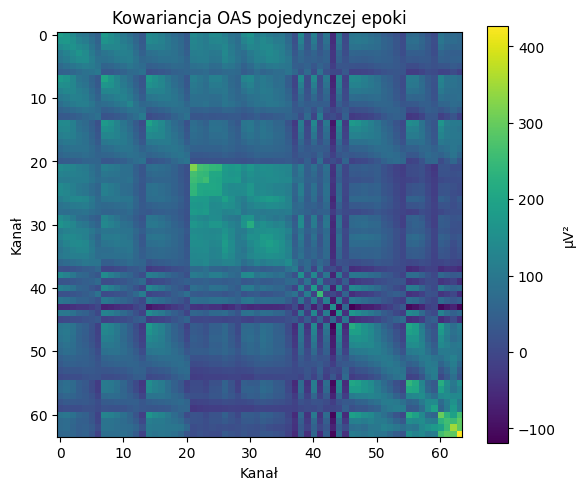

In [5]:
n = 0
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(covmat[n],cmap='viridis')
ax.set(xlabel='Kanał',ylabel='Kanał',title='Kowariancja OAS pojedynczej epoki')
fig.colorbar(im,ax=ax,label='µV²')
plt.tight_layout();plt.show()

## 5. Model MDM i metryki

In [6]:
def score_predictions(y_true, p_left, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    p_left = np.asarray(p_left, dtype=float)
    pred = (p_left >= threshold).astype(int)
    return {
        'roc_auc':float(roc_auc_score(y_true,p_left)),
        'average_precision':float(average_precision_score(y_true,p_left)),
        'accuracy':float(accuracy_score(y_true,pred)),
        'balanced_accuracy':float(balanced_accuracy_score(y_true,pred)),
        'precision':float(precision_score(y_true,pred,zero_division=0)),
        'recall':float(recall_score(y_true,pred,zero_division=0)),
        'f1':float(f1_score(y_true,pred,zero_division=0)),
    }

def prob_left(model, X_input):
    '''Pobierz dokładnie P(y=1), niezależnie od kolejności klas.'''
    classes = np.asarray(model.classes_)
    assert set(classes) == {0,1}, f'Klasy modelu: {classes}'
    return np.asarray(model.predict_proba(X_input)[:, np.where(classes==1)[0][0]], dtype=float)

## 6. Trening MDM na pięciu foldach i zapis predykcji

In [7]:
fold_results, oof_rows, validation_results = [], [], []
for fold in FOLDS_TO_RUN:
    print('\n' + '='*12 + f' FOLD {fold} ' + '='*12)
    fold_dir = RESULTS_DIR/f'fold_{fold}'
    fold_dir.mkdir(parents=True,exist_ok=True)
    tr, va, te = (splits[f'{k}_{fold}'] for k in ('train','val','test'))
    model = MDM(metric=RIEMANN_METRIC, n_jobs=MDM_N_JOBS)
    model.fit(np.asarray(covmat[tr]),y[tr])
    p_val = prob_left(model,np.asarray(covmat[va]))
    val_score = score_predictions(y[va],p_val,THRESHOLD)
    validation_results.append({'fold':int(fold),'n_val':int(len(va)),**val_score})
    p_test = prob_left(model,np.asarray(covmat[te]))
    metrics = score_predictions(y[te],p_test,THRESHOLD)
    fold_results.append({'fold':int(fold),'n_test':int(len(te)),**metrics})
    joblib.dump(model,fold_dir/'model.joblib')
    for ix,probability in zip(te,p_test):
        oof_rows.append({'model':'Riemannian MDM', 'fold':int(fold),
                         'trial_id':str(trial_ids[ix]),'subject':str(subjects[ix]),
                         'y_true':int(y[ix]),'p_left':float(probability)})
    print('Validation AUC:',round(val_score['roc_auc'],4),
          '| Test AUC:',round(metrics['roc_auc'],4),
          '| Test bal_acc:',round(metrics['balanced_accuracy'],4))

pred_df = pd.DataFrame(oof_rows)
fold_df = pd.DataFrame(fold_results)
assert pred_df['trial_id'].is_unique
assert pred_df['p_left'].between(0,1).all()
pred_df.to_csv(RESULTS_DIR/'out_of_fold_predictions.csv',index=False)
fold_df.to_csv(RESULTS_DIR/'fold_metrics.csv',index=False)
pd.DataFrame(validation_results).to_csv(RESULTS_DIR/'validation_metrics.csv',index=False)
display(fold_df.round(4))


============ FOLD 1 ============
Validation AUC: 0.5419 | Test AUC: 0.5318 | Test bal_acc: 0.506

============ FOLD 2 ============
Validation AUC: 0.547 | Test AUC: 0.527 | Test bal_acc: 0.5155

============ FOLD 3 ============
Validation AUC: 0.553 | Test AUC: 0.5451 | Test bal_acc: 0.5266

============ FOLD 4 ============
Validation AUC: 0.5136 | Test AUC: 0.5275 | Test bal_acc: 0.5009

============ FOLD 5 ============
Validation AUC: 0.5273 | Test AUC: 0.5211 | Test bal_acc: 0.508


,fold,n_test,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1
0,1,1986,0.5318,0.5307,0.5060,0.5060,0.5101,0.5065,0.5083
1,2,1914,0.5270,0.5244,0.5157,0.5155,0.5237,0.3347,0.4084
2,3,1984,0.5451,0.5428,0.5277,0.5266,0.5285,0.6195,0.5704
3,4,1980,0.5275,0.5231,0.4990,0.5009,0.5056,0.2695,0.3516
4,5,1980,0.5211,0.5292,0.5081,0.5080,0.5077,0.5661,0.5353


## 7. Odległości do średnich klas (interpretacja MDM)

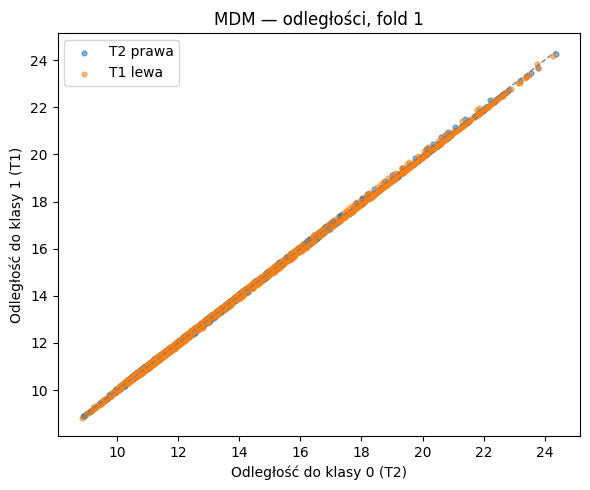

In [8]:
SHOW_FOLD=FOLDS_TO_RUN[0]
model_vis = joblib.load(RESULTS_DIR/f'fold_{SHOW_FOLD}'/'model.joblib')
te_vis=splits[f'test_{SHOW_FOLD}']
distance = model_vis.transform(np.asarray(covmat[te_vis]))
assert distance.shape[1]==2
# Indeksy klas mają własną kolejność w modelu.
ix0,ix1=(np.flatnonzero(model_vis.classes_==v)[0] for v in (0,1))
fig,ax=plt.subplots(figsize=(6,5))
for c,label in [(0,'T2 prawa'),(1,'T1 lewa')]:
    mask=y[te_vis]==c
    ax.scatter(distance[mask,ix0],distance[mask,ix1],s=12,alpha=0.55,label=label)
xy=(min(distance.min(axis=0)),max(distance.max(axis=0)))
ax.plot(xy,xy,'--',color='grey',linewidth=1)
ax.set(xlabel='Odległość do klasy 0 (T2)',ylabel='Odległość do klasy 1 (T1)',
       title=f'MDM — odległości, fold {SHOW_FOLD}')
ax.legend();plt.tight_layout();plt.show()

## 8. Macierz pomyłek i ROC

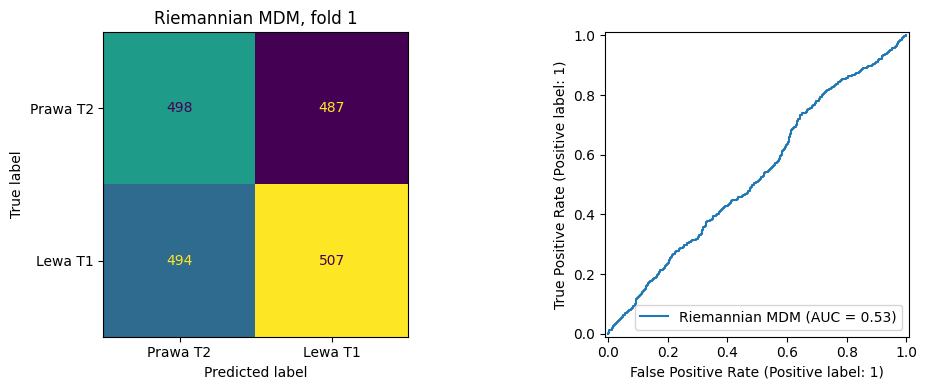

In [9]:
frame=pred_df[pred_df.fold==SHOW_FOLD]
fig,axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(frame.y_true, (frame.p_left>=THRESHOLD).astype(int),
    ax=axes[0],display_labels=['Prawa T2','Lewa T1'],colorbar=False)
RocCurveDisplay.from_predictions(frame.y_true,frame.p_left,ax=axes[1],name='Riemannian MDM')
axes[0].set_title(f'Riemannian MDM, fold {SHOW_FOLD}')
plt.tight_layout();plt.show()

## 9. Eksport raportu i ścisła kontrola foldów

In [10]:
for fold in FOLDS_TO_RUN:
    block=pred_df[pred_df.fold==fold]
    assert set(block.trial_id)==set(trial_ids[splits[f'test_{fold}']]), f'Fold {fold}: niezgodne epoki!'
complete=sorted(FOLDS_TO_RUN)==[1,2,3,4,5]
if complete:
    assert len(pred_df)==len(X) and set(pred_df.trial_id)==set(trial_ids)
report={
    'model':'Riemannian MDM', 'dataset_dir':str(DATA_DIR.resolve()),
    'demo_mode':bool(TRYB_TESTOWY),'use_ica':bool(USE_ICA),
    'n_channels':int(X.shape[1]), 'n_trials_in_dataset':int(len(X)),
    'epochs_sha256':epochs_sha256,'splits_sha256':splits_sha256,
    'folds_completed':list(map(int,FOLDS_TO_RUN)),
    'complete_out_of_fold':bool(complete and not TRYB_TESTOWY),
    'seed':SEED,'decision_threshold':THRESHOLD,
    'covariance_estimator':COVARIANCE_ESTIMATOR,'riemann_metric':RIEMANN_METRIC,
    'probability_interpretation':'Softmax(-squared distances), not calibrated',
    'fold_metrics':fold_results,
    'pooled_completed_test_folds':score_predictions(pred_df.y_true,pred_df.p_left,THRESHOLD),
    'versions':{'python':sys.version.split()[0], 'numpy':np.__version__,
                'pyriemann':pyriemann.__version__,'scikit_learn':sklearn_version},
}
(RESULTS_DIR/'results.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print('Zapisano:',RESULTS_DIR/'fold_metrics.csv')
print('Zapisano:',RESULTS_DIR/'out_of_fold_predictions.csv')
print('Następny krok: zaktualizowany notebook 03.')

Zapisano: /home/eliza/mgr-phd/results_ica_64ch/riemann_mdm/fold_metrics.csv
Zapisano: /home/eliza/mgr-phd/results_ica_64ch/riemann_mdm/out_of_fold_predictions.csv
Następny krok: zaktualizowany notebook 03.
